<a href="https://colab.research.google.com/github/Rajshree-Hada/Econ_3916_Midterm/blob/main/Econ_3916_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

🛑 This project is entirely NO AI. Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Setup

Imports only. Add any others you need here, at the top.

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [54]:
SOURCE_URL = "https://www.cdc.gov/nchs/nvss/usaleep/usaleep.html"
FILE_NAME = "data/US_A.CSV"        # the file as saved in your repository's data/ folder

SOURCE_URL = "https://www.census.gov/data/datasets/2015/demo/saipe/2015-state-and-county.html"
FILE_NAME = "data/saipe_2015.csv"

SOURCE_URL =  "https://www.ers.usda.gov/data-products/county-level-data-sets/county-level-data-sets-download-data"
FILE_NAME = "data/ers_education.csv "

SOURCE_URL = "https://www.census.gov/data/datasets/2010/dec/summary-file-1.html"
FILE_NAME = "data/tract_pop_2010.csv"

DOWNLOAD_DATE = "2026-10-29"    # YYYY-MM-DD

**Who collected it, for what purpose, what is missing and why?**

**CDC National Center for Health Statistics (NCHS) — USALEEP**

Who collected it: The CDC’s NCHS, in partnership with the National Association for Public Health Statistics and Information Systems (NAPHSIS) and the Robert Wood Johnson Foundation.

Purpose: To calculate life expectancy estimates at the ultra-local census-tract level (the U.S. Small-area Life Expectancy Estimates Project), enabling researchers to track health disparities across neighborhoods.

Missing USALEEP Tracts: There are 5,909 tracts not in USALEEP and 34 counties with zero matching tracts. NCHS suppresses life expectancy estimates for census tracts with extremely small populations or insufficient death counts over the multi-year observation window to prevent statistical instability and protect individual privacy. 526 of these unmerged tracts had a recorded population of zero.

**U.S. Census Bureau — SAIPE 2015**

Who collected it: The U.S. Census Bureau (Small Area Income and Poverty Estimates program).

Purpose: To generate timely, annual model-based estimates of income and poverty for counties and school districts between decennial censuses, primarily to guide the allocation of federal funds.

Missing SAIPE: There is 1 blank poverty cell out of 3,142 counties. Certain administrative boundaries or newly formed county equivalents lack sufficient survey sample frames to model poverty reliably in an annual release.

**USDA Economic Research Service (ERS) — Education Data**

Who collected it: The U.S. Department of Agriculture’s Economic Research Service.

Purpose: To compile and publish county-level socioeconomic data, including educational attainment and rural-urban codes, to support rural development and agricultural policy research.

Missing ERS Education and Urban-Rural Code: 20 county rows blank on education/UIC out of 3,241 total county-level rows. These gaps typically stem from geographic boundary discrepancies or the exclusion of specific territories that do not fit standard U.S. county statistical schemas.

**U.S. Census Bureau — 2010 Decennial Census**

Who collected it: The U.S. Census Bureau.

Purpose: To provide a complete, baseline count of population and housing units down to the census tract level for the entire United States.



## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

For 2015 US counties, does a higher poverty rate independently predict lower life expectancy after controlling for education and urbanicity? This question matters to public health researchers and policymakers because it isolates whether material deprivation exerts an independent structural penalty on human survival. The dataset is a product of structural measurement decisions such as small-area synthetic mortality estimation and survey-based poverty modeling—where unmerged tracts and suppressed counties are systematically related to observed population sizes, classifying the missingness mechanism as Missing at Random (MAR).

In [55]:
# The data is from CSVs in my GitHub repository
DATA = "https://raw.githubusercontent.com/Rajshree-Hada/Econ_3916_Midterm/main/"

# 1. Tract level life expectancy, USALEEP and 2010 Census tract population
usaleep = pd.read_csv(DATA + "US_A.CSV")
pop = pd.read_csv(DATA + "tract_pop_2010.csv")
print("USALEEP tracts:", len(usaleep), "population file rows:", len(pop))

# read_csv reads Tract ID as a number, so codes lose their leading zero:Both files lose it so the merge still matches.
tracts = usaleep.merge(pop, on="Tract ID", how="left", validate="one_to_one", indicator=True)
print(tracts["_merge"].value_counts().to_string())
tracts_no_pop = (tracts["_merge"] == "left_only").sum()
tracts_zero_pop = (tracts["pop2010"] == 0).sum()
print("tracts with no population match:", tracts_no_pop, "tracts with population 0:", tracts_zero_pop)

USALEEP tracts: 67148 population file rows: 73057
_merge
both          67148
left_only         0
right_only        0
tracts with no population match: 0 tracts with population 0: 0


In [56]:
# 2. Tracts to counties by dividing the last 6 digits out
tracts = tracts[tracts["pop2010"] > 0].copy()
tracts["county"] = tracts["Tract ID"] // 1_000_000
tracts["le_x_pop"] = tracts["e(0)"] * tracts["pop2010"]

g = tracts.groupby("county")
county = pd.DataFrame({
    "life_exp": g["le_x_pop"].sum() / g["pop2010"].sum(),   # population-weighted mean of the tracts
    "simple_le": g["e(0)"].mean(),                          # the simple mean
    "n_tracts": g.size(),
    "pop": g["pop2010"].sum()}).reset_index()
print("counties:", len(county))
print("largest gap between weighted and simple mean (years):", round((county["life_exp"] - county["simple_le"]).abs().max(), 2))

counties: 3108
largest gap between weighted and simple mean (years): 3.08


In [57]:
# 3. All county files: poverty (SAIPE 2015) and education + urban code (ERS)
saipe = pd.read_csv(DATA + "saipe_2015.csv")
saipe = saipe[saipe["County FIPS Code"] != 0].copy()
saipe["county"] = saipe["State FIPS Code"] * 1000 + saipe["County FIPS Code"]
saipe["poverty"] = pd.to_numeric(saipe["Poverty Percent, All Ages"], errors="coerce")
saipe = saipe[["county", "poverty"]]

ers = pd.read_csv(DATA + "ers_education.csv", encoding="cp1252")
ers = ers.rename(columns={
    "FIPS Code": "county",
    "Area name": "name",
    "Percent of adults who are not high school graduates, 2008-12": "less_hs",
    "2013 Urban Influence Code": "uic"})
ers = ers[["county", "name", "less_hs", "uic"]]
print("SAIPE counties:", len(saipe), "| ERS rows:", len(ers))

SAIPE counties: 3142 | ERS rows: 3294


In [58]:
# 4. The join
df = county.merge(saipe, on="county", how="left", validate="one_to_one", indicator=True)
print("SAIPE merge:", df["_merge"].value_counts().to_dict())
poverty_unmatched = (df["_merge"] == "left_only").sum()
df = df.drop(columns="_merge")

df = df.merge(ers, on="county", how="left", validate="one_to_one", indicator=True)
print("ERS merge:", df["_merge"].value_counts().to_dict())
ers_unmatched = (df["_merge"] == "left_only").sum()
df = df.drop(columns="_merge")

print("\nMissing values after the joins:")
print(df[["life_exp", "poverty", "less_hs", "uic"]].isna().sum().to_string())

SAIPE merge: {'both': 3108, 'left_only': 0, 'right_only': 0}
ERS merge: {'both': 3108, 'left_only': 0, 'right_only': 0}

Missing values after the joins:
life_exp    0
poverty     0
less_hs     0
uic         0


In [59]:
# 5. Missingness by file

# USALEEP
print("USALEEP blank cells:", usaleep.isna().sum().sum())
absent = pop.merge(usaleep[["Tract ID", "e(0)"]], on="Tract ID", how="left", indicator=True)
absent["status"] = np.where(absent["_merge"] == "both", "in USALEEP", "not in USALEEP")
print(absent["status"].value_counts().to_string())
print(absent.groupby("status")["pop2010"].describe().round(0).to_string())
tracts_not_in_usaleep = (absent["_merge"] == "left_only").sum()
zero_pop_absent = ((absent["_merge"] == "left_only") & (absent["pop2010"] == 0)).sum()
print("not in USALEEP and population 0:", zero_pop_absent)

# Tract population file
print("\nPopulation file blank cells:", pop.isna().sum().sum())

# SAIPE
saipe_missing = saipe["poverty"].isna().sum()
no_tracts = saipe[~saipe["county"].isin(county["county"])]
counties_no_tracts = len(no_tracts)
print("\nSAIPE counties:", len(saipe), "| blank poverty:", saipe_missing)
print("SAIPE counties with no USALEEP tracts:", counties_no_tracts)
print(sorted(no_tracts["county"]))

# ERS
real = ers[ers["county"] % 1000 != 0]
ers_blank_county_rows = real["less_hs"].isna().sum()
print("\nERS rows:", len(ers), "| county-level rows:", len(real))
print("county-level rows blank on less_hs:", ers_blank_county_rows, "| blank on uic:", real["uic"].isna().sum())
print("blank cells among the", len(county), "counties in the analysis:", real[real["county"].isin(county["county"])][["less_hs", "uic"]].isna().sum().sum())

USALEEP blank cells: 0
status
in USALEEP        67148
not in USALEEP     5909
                  count    mean     std    min     25%     50%     75%      max
status                                                                         
in USALEEP      67148.0  4324.0  1915.0  549.0  2976.0  4070.0  5370.0  33201.0
not in USALEEP   5909.0  3112.0  2350.0    0.0  1410.0  2900.0  4479.0  37452.0
not in USALEEP and population 0: 526

Population file blank cells: 0

SAIPE counties: 3142 | blank poverty: 1
SAIPE counties with no USALEEP tracts: 34
[2068, 2158, 2282, 8079, 8111, 15005, 16033, 30037, 30069, 30103, 31005, 31007, 31009, 31075, 31091, 31103, 31115, 31117, 31171, 32009, 35021, 38087, 46061, 46075, 46091, 46102, 48033, 48261, 48263, 48269, 48271, 48301, 48311, 49009]

ERS rows: 3294 | county-level rows: 3241
county-level rows blank on less_hs: 20 | blank on uic: 20
blank cells among the 3108 counties in the analysis: 0


In [60]:
# 6
rows_before = len(df)
df = df.dropna(subset=["life_exp", "poverty", "less_hs", "uic"]).copy()
print(rows_before, "->", len(df), "counties")

# Metro county (0/1): Urban Influence Codes 1 and 2 are the two metro categories.
df["metro"] = np.where(df["uic"] <= 2, 1, 0)

3108 -> 3108 counties


In [83]:
# Summary-statistics table
summary_vars = {
    "life_exp": "Life expectancy at birth (years, population-weighted)",
    "poverty": "Poverty rate, all ages (%)",
    "less_hs": "Adults 25+ without a high school diploma (%, 2008-12)",
    "metro": "Metro county (0/1)",
    "n_tracts": "Census tracts in the county (count)",
    "pop": "Population, 2010 (people)"}
table = df[list(summary_vars)].describe().T[["count", "mean", "50%", "min", "max", "std"]]
table.index = [summary_vars[v] for v in table.index]
table.columns = ["N", "Mean", "Median", "Min", "Max", "STD"]
print(table.round(1).to_string())

                                                            N     Mean   Median    Min        Max       STD
Life expectancy at birth (years, population-weighted)  3108.0     77.8     77.8   68.9       89.5       2.6
Poverty rate, all ages (%)                             3108.0     16.3     15.2    3.4       47.4       6.5
Adults 25+ without a high school diploma (%, 2008-12)  3108.0     15.9     14.5    2.5       55.1       7.0
Metro county (0/1)                                     3108.0      0.4      0.0    0.0        1.0       0.5
Census tracts in the county (count)                    3108.0     21.6      6.0    1.0     2195.0      68.0
Population, 2010 (people)                              3108.0  93423.0  25716.0  763.0  9410747.0  294953.6


In [62]:
#Report of Section 1
UNIT = "county"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "life_exp"     # your dependent variable's column name
MAIN_X = "poverty"      # your main explanatory variable's column name
CONTROLS = ["less_hs", "metro"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")

Rows: 3,108   Columns: 10   One row is: county

Missing values per column:
life_exp    0
poverty     0
less_hs     0
metro       0

Skew of life_exp: 0.25 (above about 1, consider a log)


*Your words here.*

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

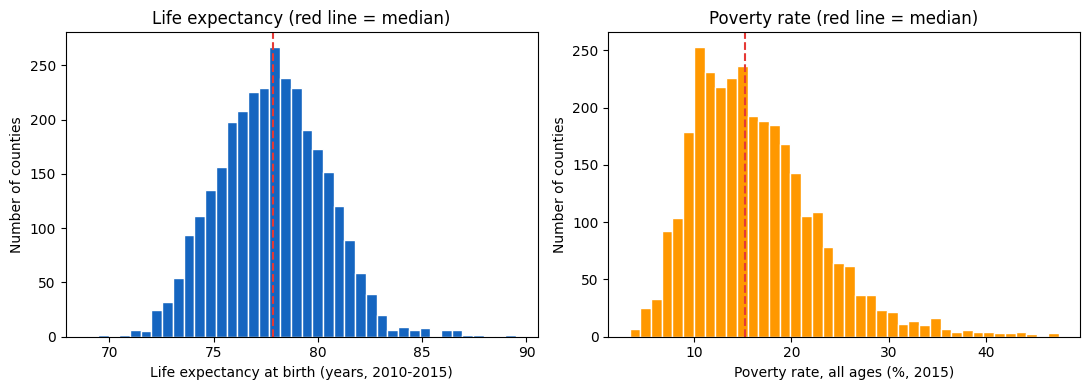

Skew of life expectancy: 0.25
Skew of poverty rate: 1.07
Median life expectancy: 77.8 | mean: 77.8


In [63]:
# Figure 1
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["life_exp"], bins=40, color="#1565C0", edgecolor="white")
axes[0].axvline(df["life_exp"].median(), color="#E53935", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Life expectancy at birth (years, 2010-2015)")
axes[0].set_ylabel("Number of counties")
axes[0].set_title("Life expectancy (red line = median)")

axes[1].hist(df["poverty"], bins=40, color="#FF9800", edgecolor="white")
axes[1].axvline(df["poverty"].median(), color="#E53935", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Poverty rate, all ages (%, 2015)")
axes[1].set_ylabel("Number of counties")
axes[1].set_title("Poverty rate (red line = median)")

fig.tight_layout()
fig.savefig("figures/fig1_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Skew of life expectancy:", round(df["life_exp"].skew(), 2))
print("Skew of poverty rate:", round(df["poverty"].skew(), 2))
print("Median life expectancy:", round(df["life_exp"].median(), 1), "| mean:", round(df["life_exp"].mean(), 1))

Figure 1. Life expectancy is roughly symmetric around its median of 77.8 years, while poverty piles up at low rates and has a long right tail (median 15.2%, mean 16.3%). The red dashed lines mark the medians.

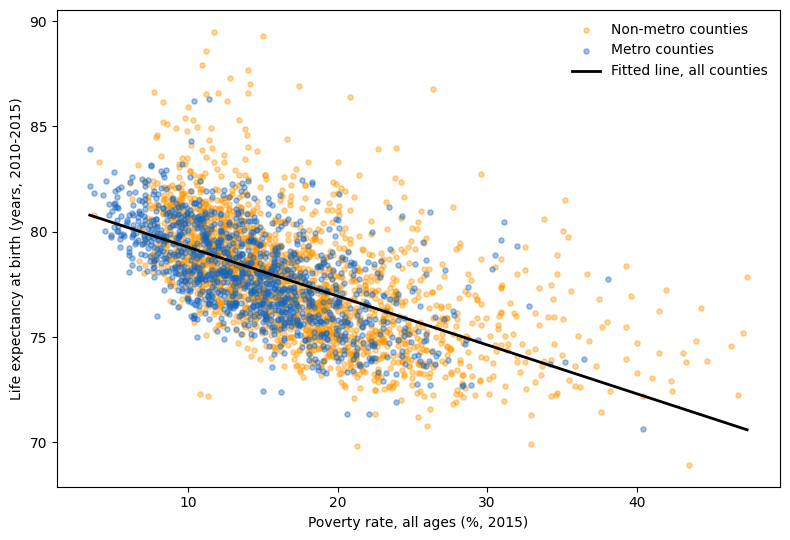

Correlation, poverty and life expectancy: -0.58
Slope of the fitted line (years per percentage point): -0.232
       poverty  life_exp
metro                   
0         17.4      77.7
1         14.4      78.0


In [64]:
# Figure 2
line = sm.OLS(df["life_exp"], sm.add_constant(df[["poverty"]])).fit().params   # the simple fitted line, for the picture
x_line = np.linspace(df["poverty"].min(), df["poverty"].max(), 100)
y_line = line["const"] + line["poverty"] * x_line

fig, ax = plt.subplots(figsize=(8, 5.5))
nonmetro = df[df["metro"] == 0]
metro = df[df["metro"] == 1]
ax.scatter(nonmetro["poverty"], nonmetro["life_exp"], s=14, alpha=0.4, color="#FF9800", label="Non-metro counties")
ax.scatter(metro["poverty"], metro["life_exp"], s=14, alpha=0.4, color="#1565C0", label="Metro counties")
ax.plot(x_line, y_line, color="black", linewidth=2, label="Fitted line, all counties")
ax.set_xlabel("Poverty rate, all ages (%, 2015)")
ax.set_ylabel("Life expectancy at birth (years, 2010-2015)")
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig("figures/fig2_poverty_life_expectancy.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation, poverty and life expectancy:", round(df["poverty"].corr(df["life_exp"]), 2))
print("Slope of the fitted line (years per percentage point):", round(line["poverty"], 3))
print(df.groupby("metro")[["poverty", "life_exp"]].mean().round(1).to_string())

Figure 2. Counties with higher poverty have lower life expectancy: the correlation is −0.58 and the fitted line falls 0.232 years per percentage point. Non-metro counties (orange) are more spread out and include most of the longest-lived counties.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [65]:
y = df["life_exp"]
X1 = sm.add_constant(df[["poverty"]])
X2 = sm.add_constant(df[["poverty", "less_hs", "metro"]])
m1 = sm.OLS(y, X1).fit(cov_type="HC3", use_t=True)
m2 = sm.OLS(y, X2).fit(cov_type="HC3", use_t=True)

labels = {"poverty": "Poverty rate (%)", "less_hs": "No high school diploma (%)",
          "metro": "Metro county (0/1)", "const": "Constant"}
print(f"{'':<28}{'(1) Poverty only':>20}{'(2) With controls':>20}")
print("-" * 68)
for name in ["poverty", "less_hs", "metro", "const"]:
    row_coef, row_se = f"{labels[name]:<28}", f"{'':<28}"
    for m in [m1, m2]:
        if name in m.params.index:
            row_coef += f"{m.params[name]:>20.3f}"
            row_se += f"{'(' + format(m.bse[name], '.3f') + ')':>20}"
        else:
            row_coef += f"{'':>20}"
            row_se += f"{'':>20}"
    print(row_coef)
    print(row_se)
print("-" * 68)
print(f"{'N':<28}{int(m1.nobs):>20}{int(m2.nobs):>20}")
print(f"{'R-squared':<28}{m1.rsquared:>20.3f}{m2.rsquared:>20.3f}")
print("Dependent variable: county life expectancy at birth (years). Robust (HC3) standard errors in parentheses.")

                                (1) Poverty only   (2) With controls
--------------------------------------------------------------------
Poverty rate (%)                          -0.232              -0.169
                                         (0.007)             (0.010)
No high school diploma (%)                                    -0.094
                                                             (0.010)
Metro county (0/1)                                            -0.460
                                                             (0.074)
Constant                                  81.581              82.225
                                         (0.111)             (0.127)
--------------------------------------------------------------------
N                                           3108                3108
R-squared                                  0.340               0.379
Dependent variable: county life expectancy at birth (years). Robust (HC3) standard errors in parenthese

*Your words here.*

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

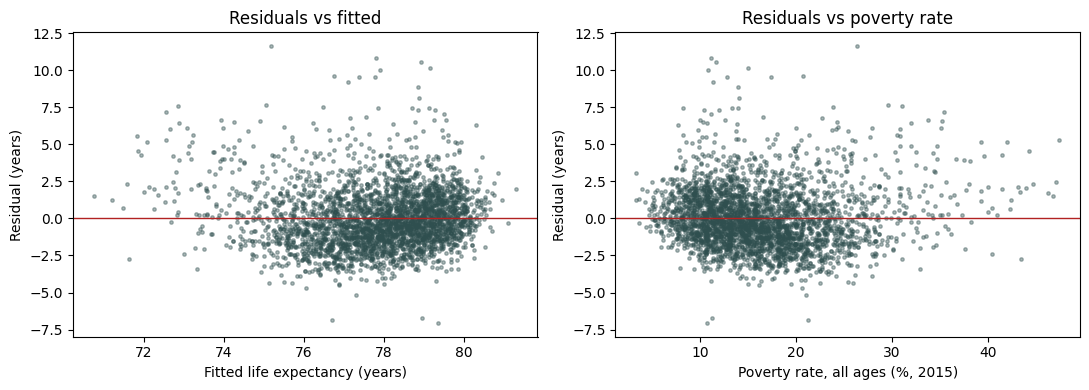

Residual range: -7.0 to 11.6 | SD: 2.02


In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(m2.fittedvalues, m2.resid, s=6, alpha=0.4, color="darkslategray")
axes[0].axhline(0, color="firebrick", lw=1)
axes[0].set_xlabel("Fitted life expectancy (years)")
axes[0].set_ylabel("Residual (years)")
axes[0].set_title("Residuals vs fitted")

axes[1].scatter(df["poverty"], m2.resid, s=6, alpha=0.4, color="darkslategray")
axes[1].axhline(0, color="firebrick", lw=1)
axes[1].set_xlabel("Poverty rate, all ages (%, 2015)")
axes[1].set_ylabel("Residual (years)")
axes[1].set_title("Residuals vs poverty rate")

fig.tight_layout()
fig.savefig("figures/fig3_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print("Residual range:", round(m2.resid.min(), 1), "to", round(m2.resid.max(), 1), "| SD:", round(m2.resid.std(), 2))

Figure 3. Residuals center on zero with a long positive tail and a spread that varies with poverty and with fitted life expectancy, which is why inference uses robust standard errors (Breusch–Pagan p < 0.001).

In [67]:
bp = het_breuschpagan(m2.resid, m2.model.exog)
print(f"Breusch-Pagan p-value: {bp[1]:.2e}")

classical = sm.OLS(y, X2).fit()

print(f"\n{'term':<12}{'coef':>10}{'classical SE':>14}{'HC3 SE':>10}{'ratio':>8}")
print("-" * 54)
for name in m2.params.index:
    ratio = m2.bse[name] / classical.bse[name]
    print(f"{name:<12}{m2.params[name]:>10.4f}{classical.bse[name]:>14.4f}{m2.bse[name]:>10.4f}{ratio:>8.2f}")

Breusch-Pagan p-value: 3.58e-22

term              coef  classical SE    HC3 SE   ratio
------------------------------------------------------
const          82.2254        0.1144    0.1271    1.11
poverty        -0.1692        0.0078    0.0100    1.29
less_hs        -0.0937        0.0071    0.0099    1.39
metro          -0.4601        0.0771    0.0738    0.96


In [68]:
Xv = X2.values

print(f"{'term':<12}{'VIF':>8}")
print("-" * 20)
vif_values = {}
for i, name in enumerate(X2.columns):
    if name != "const":
        vif_values[name] = variance_inflation_factor(Xv, i)
        print(f"{name:<12}{vif_values[name]:>8.2f}")

term             VIF
--------------------
poverty         1.93
less_hs         1.91
metro           1.06


In [69]:
infl = classical.get_influence()
lev = infl.hat_matrix_diag
std_resid = infl.resid_studentized_internal
cooks = infl.cooks_distance[0]

order = np.argsort(cooks)[::-1][:5]

top5 = df.iloc[order][["name", "poverty", "less_hs", "metro", "life_exp"]].copy()
top5["leverage"] = lev[order]
top5["std_resid"] = std_resid[order]
top5["cooks_d"] = cooks[order]
print(top5.round(3).to_string(index=False))

share = cooks[order].sum() / cooks.sum()
print(f"\n5 of {len(df):,} counties ({5 / len(df):.2%}) carry {share:.0%} of the total Cook's distance")

keep = df.drop(df.index[order])
X_keep = sm.add_constant(keep[["poverty", "less_hs", "metro"]])
m2_drop = sm.OLS(keep["life_exp"], X_keep).fit(cov_type="HC3", use_t=True)
print(f"\nPoverty coefficient, all counties: {m2.params['poverty']:.4f}")
print(f"Poverty coefficient, without the five most influential: {m2_drop.params['poverty']:.4f}")

          name  poverty  less_hs  metro  life_exp  leverage  std_resid  cooks_d
 Holmes County     10.8     44.5      0    82.648     0.014      3.195    0.036
 Martin County     11.4     29.3      1    86.319     0.005      4.572    0.025
Haskell County     11.2     27.0      0    88.600     0.003      5.347    0.025
 Corson County     47.4     17.6      0    77.862     0.014      2.640    0.024
  Starr County     30.9     55.1      0    77.389     0.012      2.762    0.023

5 of 3,108 counties (0.16%) carry 10% of the total Cook's distance

Poverty coefficient, all counties: -0.1692
Poverty coefficient, without the five most influential: -0.1645


*Your words here.*

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

For the poverty coefficient to be causal, counties with different poverty rates would have to be alike in everything else that affects how long people live, apart from the education and metro status that are controled for. I don’t think that holds. Health and poverty probably run in both directions, because illness lowers earnings and raises medical costs, so low life expectancy can push poverty up as well as the reverse. Things I did not measure, such as smoking, obesity, age and racial composition, access to health care, and regional factors, plausibly raise poverty and shorten life at the same time. Education is also an uncertain control, since it may partly be a result of poverty, so controlling for it could understate poverty’s total association. Adding education and metro status moves the poverty coefficient from -0.232 to -0.169, which shows how much of the raw gap overlaps with them and says nothing about what remains. Measurement adds more doubt. SAIPE poverty is a model-based estimate, life expectancy comes from modelled tract estimates averaged to counties, 5,909 tracts and 34 small counties are missing, and county averages say nothing about individuals. Neighbouring counties are also unlikely to be independent, so the standard errors may be too small. My estimate is therefore a conditional association: counties with a poverty rate one percentage point higher, and the same adult education and metro status, have about 0.17 fewer years of life expectancy.

The negative association is large relative to its uncertainty. The VIFs are below 2, the largest Cook’s distance is 0.036, and dropping the five most influential counties barely moves the coefficient (-0.169 to -0.165). Breusch-Pagan rejects constant variance which is why robust standard errors are reported. The  sign and rough size should be trusted but not read as the effect of reducing poverty. The model explains 38% of the variation, and the typical residual is about 2 years. With another month I would cluster by state or add state fixed effects, add health-behaviour and demographic controls, weight by pooled population as USALEEP does, and use changes in poverty over time instead of one cross-section.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [70]:
# Appendix A: regression table for model (2), robust (HC3) standard errors
ci = m2.conf_int()
print(f"{'term':<28}{'coef':>9}{'SE':>9}{'p':>9}{'95% CI':>22}")
print("-" * 77)
for name in m2.params.index:
    interval = f"[{ci.loc[name, 0]:.3f}, {ci.loc[name, 1]:.3f}]"
    print(f"{labels[name]:<28}{m2.params[name]:>9.3f}{m2.bse[name]:>9.3f}{m2.pvalues[name]:>9.3f}{interval:>22}")
print(f"N = {int(m2.nobs)}   R-squared = {m2.rsquared:.3f}")

# Appendix B: the diagnostics for model (2)
print(f"\nBreusch-Pagan p-value: {bp[1]:.2e}")
for name in vif_values:
    print(f"VIF, {name}: {vif_values[name]:.2f}")
print(f"Largest Cook's distance: {cooks.max():.3f}")
print(top5.round(3).to_string(index=False))
print(f"Poverty coefficient without the five most influential: {m2_drop.params['poverty']:.4f}")

term                             coef       SE        p                95% CI
-----------------------------------------------------------------------------
Constant                       82.225    0.127    0.000      [81.976, 82.475]
Poverty rate (%)               -0.169    0.010    0.000      [-0.189, -0.150]
No high school diploma (%)     -0.094    0.010    0.000      [-0.113, -0.074]
Metro county (0/1)             -0.460    0.074    0.000      [-0.605, -0.315]
N = 3108   R-squared = 0.379

Breusch-Pagan p-value: 3.58e-22
VIF, poverty: 1.93
VIF, less_hs: 1.91
VIF, metro: 1.06
Largest Cook's distance: 0.036
          name  poverty  less_hs  metro  life_exp  leverage  std_resid  cooks_d
 Holmes County     10.8     44.5      0    82.648     0.014      3.195    0.036
 Martin County     11.4     29.3      1    86.319     0.005      4.572    0.025
Haskell County     11.2     27.0      0    88.600     0.003      5.347    0.025
 Corson County     47.4     17.6      0    77.862     0.014     

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [84]:
REPORT_NUMBERS = {
    # "Section 1: rows in the final sample": ...,
    # "Section 3: coefficient on <your main predictor>": ...,
    "Section 1: USALEEP tracts": len(usaleep),
    "Section 1: tracts with no population match": tracts_no_pop,
    "Section 1: tracts with population 0": tracts_zero_pop,
    "Section 1: counties built from tracts": len(county),
    "Section 1: counties with no SAIPE match": poverty_unmatched,
    "Section 1: counties with no ERS match": ers_unmatched,
    "Section 1: tracts in the 2010 population file but not in USALEEP": tracts_not_in_usaleep,
    "Section 1: of those, tracts with population 0": zero_pop_absent,
    "Section 1: SAIPE counties with a blank poverty value": saipe_missing,
    "Section 1: SAIPE counties with no USALEEP tracts": counties_no_tracts,
    "Section 1: ERS county-level rows blank on education": ers_blank_county_rows,
    "Section 1: rows in the final sample": len(df),
    "Section 1: Life expectancy count": df["life_exp"].count(),
    "Section 1: Life expectancy mean": df["life_exp"].mean(),
    "Section 1: Life expectancy median": df["life_exp"].median(),
    "Section 1: Life expectancy min": df["life_exp"].min(),
    "Section 1: Life expectancy max": df["life_exp"].max(),
    "Section 1: Life expectancy std": df["life_exp"].std(),
    "Section 1: Poverty rate count": df["poverty"].count(),
    "Section 1: Poverty rate mean": df["poverty"].mean(),
    "Section 1: Poverty rate median": df["poverty"].median(),
    "Section 1: Poverty rate min": df["poverty"].min(),
    "Section 1: Poverty rate max": df["poverty"].max(),
    "Section 1: Poverty rate std": df["poverty"].std(),
    "Section 1: Less than high school count": df["less_hs"].count(),
    "Section 1: Less than high school mean": df["less_hs"].mean(),
    "Section 1: Less than high school median": df["less_hs"].median(),
    "Section 1: Less than high school min": df["less_hs"].min(),
    "Section 1: Less than high school max": df["less_hs"].max(),
    "Section 1: Less than high school std": df["less_hs"].std(),
    "Section 1: Metro county count": df["metro"].count(),
    "Section 1: Metro county mean": df["metro"].mean(),
    "Section 1: Metro county median": df["metro"].median(),
    "Section 1: Metro county min": df["metro"].min(),
    "Section 1: Metro county max": df["metro"].max(),
    "Section 1: Metro county std": df["metro"].std(),
    "Section 1: Census tracts count": df["n_tracts"].count(),
    "Section 1: Census tracts mean": df["n_tracts"].mean(),
    "Section 1: Census tracts median": df["n_tracts"].median(),
    "Section 1: Census tracts min": df["n_tracts"].min(),
    "Section 1: Census tracts max": df["n_tracts"].max(),
    "Section 1: Census tracts std": df["n_tracts"].std(),
    "Section 1: Population count": df["pop"].count(),
    "Section 1: Population mean": df["pop"].mean(),
    "Section 1: Population median": df["pop"].median(),
    "Section 1: Population min": df["pop"].min(),
    "Section 1: Population max": df["pop"].max(),
    "Section 1: Population std": df["pop"].std(),
    "Section 2: skew of life expectancy": f"{df["life_exp"].skew():.3f}",
    "Section 2: skew of poverty rate": f"{df["poverty"].skew():.3f}",
    "Section 2: correlation, poverty and life expectancy": f"{df["poverty"].corr(df["life_exp"]):.3f}",
    "Section 3: coefficient on poverty, model (2)": f"{m2.params["poverty"]:.3f}",
    "Section 3: robust SE on poverty, model (2)": f"{m2.bse["poverty"]:.3f}",
    "Section 4: Breusch-Pagan p-value": f"{bp[1]:.3f}",
    "Section 4: largest VIF": f"{max(vif_values.values()):.3f}",
    "Section 4: largest Cook's distance": f"{cooks.max():.3f}",
    "Section 4: poverty coefficient without the five most influential": f"{m2_drop.params["poverty"]:.3f}",
    "Appendix: poverty 95% CI lower, model (2)": f"{ci.loc["poverty", 0]:.3f}",
    "Appendix: poverty 95% CI upper, model (2)": f"{ci.loc["poverty", 1]:.3f}",
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: USALEEP tracts: 67148
Section 1: tracts with no population match: 0
Section 1: tracts with population 0: 0
Section 1: counties built from tracts: 3108
Section 1: counties with no SAIPE match: 0
Section 1: counties with no ERS match: 0
Section 1: tracts in the 2010 population file but not in USALEEP: 5909
Section 1: of those, tracts with population 0: 526
Section 1: SAIPE counties with a blank poverty value: 1
Section 1: SAIPE counties with no USALEEP tracts: 34
Section 1: ERS county-level rows blank on education: 20
Section 1: rows in the final sample: 3108
Section 1: Life expectancy count: 3108
Section 1: Life expectancy mean: 77.8066334977932
Section 1: Life expectancy median: 77.83155122320204
Section 1: Life expectancy min: 68.92834872979213
Section 1: Life expectancy max: 89.5
Section 1: Life expectancy std: 2.5664238848319134
Section 1: Poverty rate count: 3108
Section 1: Poverty rate mean: 16.295045045045047
Section 1: Poverty rate median: 15.2
Section 1: Poverty rate

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.